⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest Keltner Slope + Ichimoku Strategy...

METRICS (Keltner Slope + Ichimoku Strategy)
     Final Equity: 10224.2353
     Total Return: 0.0224
    CAGR (approx): 0.0112
     Max Drawdown: -0.1938
           Sharpe: 0.1522
           Trades: 641
          Winrate: 0.3978
    Avg PnL/Trade: 0.3498
    Profit Factor: 1.0089
           Max DD: -0.193793859125


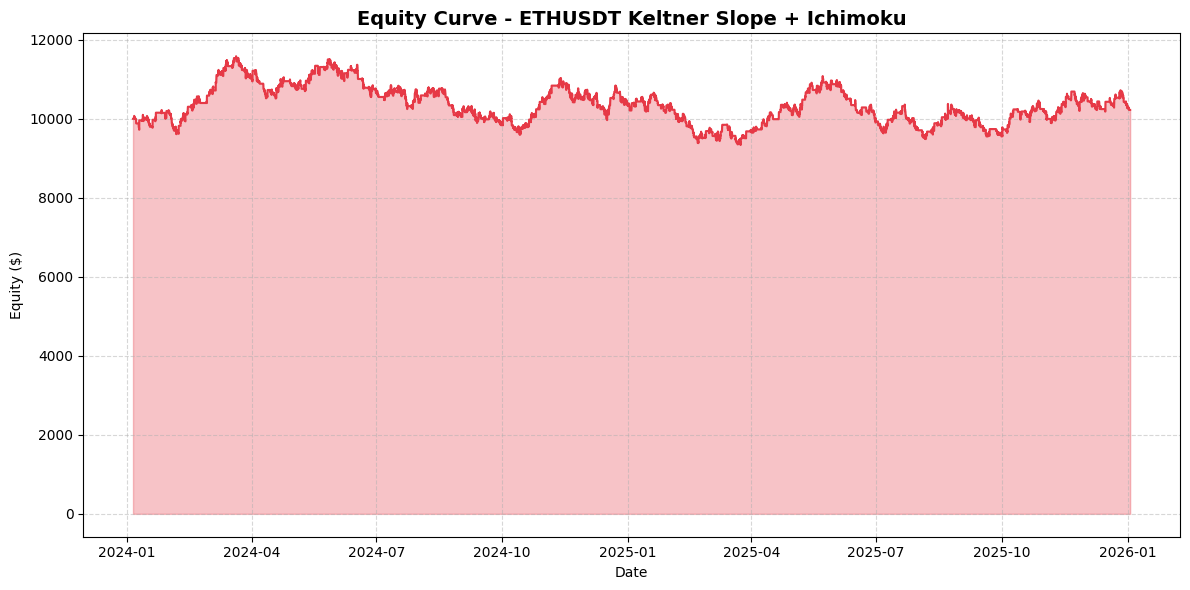


📊 Sample Trades (first 10):
            Exit Time   Type        Entry         Exit         PnL         Reason       Balance
0 2024-01-06 14:00:00  SHORT  2248.947257  2248.269265    1.668706  Trailing Stop  10001.668706
1 2024-01-07 15:00:00   LONG  2253.562287  2224.446373 -119.110103  Trailing Stop   9882.558603
2 2024-01-09 13:00:00   LONG  2298.770000  2261.511159  -98.825586      Stop Loss   9783.733017
3 2024-01-09 21:00:00   LONG  2276.803139  2353.892884  176.107194    Take Profit   9959.840212
4 2024-01-12 15:00:00   LONG  2599.730000  2662.372840   82.734160  Trailing Stop  10042.574372
5 2024-01-12 21:00:00   LONG  2584.440000  2503.826241 -100.425744      Stop Loss   9942.148628
6 2024-01-14 11:00:00   LONG  2501.321330  2535.728417   41.448691  Trailing Stop   9983.597319
7 2024-01-15 18:00:00  SHORT  2540.750000  2544.794289  -10.882271  Trailing Stop   9972.715049
8 2024-01-16 08:00:00  SHORT  2534.690000  2544.421551  -26.272974  Trailing Stop   9946.442075
9 2024-01-1

In [9]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- 1. HÀM TẢI DỮ LIỆU ---
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")
    
    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data: break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05) 
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines: return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# --- 2. HÀM TÍNH CHỈ BÁO ---
def calculate_indicators(df):
    data = df.copy()
    
    # True Range
    data['prev_close'] = data['Close'].shift(1)
    data['h_l'] = data['High'] - data['Low']
    data['h_pc'] = (data['High'] - data['prev_close']).abs()
    data['l_pc'] = (data['Low'] - data['prev_close']).abs()
    data['TR'] = data[['h_l', 'h_pc', 'l_pc']].max(axis=1)
    
    # ATR function
    def calc_atr(series_tr, period):
        return series_tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    
    # ATR các period
    data['ATR_20'] = calc_atr(data['TR'], 20)
    data['ATR_40'] = calc_atr(data['TR'], 40)
    data['ATR_90'] = calc_atr(data['TR'], 90)
    
    # Keltner Channel (20, mult=2.3)
    data['EMA_20'] = data['Close'].ewm(span=20, adjust=False).mean()
    data['KC_Upper'] = data['EMA_20'] + (2.3 * data['ATR_20'])
    data['KC_Lower'] = data['EMA_20'] - (2.3 * data['ATR_20'])
    
    # Ichimoku Components
    # Tenkan-sen (Conversion Line) = (9-period high + 9-period low) / 2
    # Theo code: IchimokuTenkanPeriod = 87
    tenkan_period = 87
    kijun_period = 26
    senkou_period = 52
    
    # Tenkan-sen: (highest high + lowest low) / 2 over tenkan_period
    data['Tenkan_High'] = data['High'].rolling(window=tenkan_period).max()
    data['Tenkan_Low'] = data['Low'].rolling(window=tenkan_period).min()
    data['Tenkan_Sen'] = (data['Tenkan_High'] + data['Tenkan_Low']) / 2
    
    # Kijun-sen: (highest high + lowest low) / 2 over kijun_period
    data['Kijun_High'] = data['High'].rolling(window=kijun_period).max()
    data['Kijun_Low'] = data['Low'].rolling(window=kijun_period).min()
    data['Kijun_Sen'] = (data['Kijun_High'] + data['Kijun_Low']) / 2
    
    # Senkou Span A: (Tenkan + Kijun) / 2, shifted forward
    data['Senkou_A'] = ((data['Tenkan_Sen'] + data['Kijun_Sen']) / 2).shift(kijun_period)
    
    # Senkou Span B: (highest high + lowest low) / 2 over senkou_period, shifted forward
    data['Senkou_High'] = data['High'].rolling(window=senkou_period).max()
    data['Senkou_Low'] = data['Low'].rolling(window=senkou_period).min()
    data['Senkou_B'] = ((data['Senkou_High'] + data['Senkou_Low']) / 2).shift(kijun_period)
    
    data.dropna(inplace=True)
    return data

# --- 3. BACKTESTER ---
class KeltnerIchimokuBacktester:
    def __init__(self, df, initial_balance=10000):
        self.df = df
        self.initial_balance = initial_balance
        self.balance = initial_balance
        self.equity_curve = [] 
        self.trades = []
        self.position = None 
        self.entry_price = 0
        self.sl = 0
        self.tp = 0
        self.entry_bar_idx = 0
        self.qty = 0
        self.pending_order = None 
        self.trailing_sl = None
        
        # Strategy Parameters
        self.risk_pct = 0.01  # 1%
        self.sl_coef = 2.0  # SL = 2 * ATR(20)
        self.tp_coef = 3.6  # TP = 3.6 * ATR(20)
        self.price_entry_mult = 0.8  # Entry buffer
        self.trailing_coef = 1.5  # Trailing = 1.5 * ATR(90)
        self.exit_after_bars = 40
        self.pending_expiration = 6
        
    def run(self):
        indices = self.df.index
        
        for i in range(len(self.df)):
            current_bar = self.df.iloc[i]
            idx = indices[i]
            
            # A. QUẢN LÝ LỆNH ĐANG MỞ
            if self.position is not None:
                # Check Exit After Bars
                bars_held = i - self.entry_bar_idx
                if bars_held >= self.exit_after_bars:
                    self.close_position(current_bar['Close'], idx, "Time Exit")
                    self.append_equity(idx)
                    continue
                
                # Check SL/TP
                if self.position == 'LONG':
                    # Check Trailing Stop first
                    if self.trailing_sl is not None:
                        if current_bar['Low'] <= self.trailing_sl:
                            self.close_position(self.trailing_sl, idx, "Trailing Stop")
                            self.append_equity(idx)
                            continue
                    
                    # Regular SL
                    if current_bar['Low'] <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    
                    # TP
                    if current_bar['High'] >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                    
                    # Update Trailing Stop (based on ATR(90))
                    trailing_distance = self.trailing_coef * current_bar['ATR_90']
                    new_trailing_sl = current_bar['Close'] - trailing_distance
                    
                    # Only move trailing stop up, never down
                    if self.trailing_sl is None or new_trailing_sl > self.trailing_sl:
                        self.trailing_sl = new_trailing_sl
                        # Update main SL if trailing is better
                        self.sl = max(self.sl, self.trailing_sl)
                
                elif self.position == 'SHORT':
                    # Check Trailing Stop first
                    if self.trailing_sl is not None:
                        if current_bar['High'] >= self.trailing_sl:
                            self.close_position(self.trailing_sl, idx, "Trailing Stop")
                            self.append_equity(idx)
                            continue
                    
                    # Regular SL
                    if current_bar['High'] >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    
                    # TP
                    if current_bar['Low'] <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                    
                    # Update Trailing Stop
                    trailing_distance = self.trailing_coef * current_bar['ATR_90']
                    new_trailing_sl = current_bar['Close'] + trailing_distance
                    
                    # Only move trailing stop down, never up
                    if self.trailing_sl is None or new_trailing_sl < self.trailing_sl:
                        self.trailing_sl = new_trailing_sl
                        # Update main SL if trailing is better
                        self.sl = min(self.sl, self.trailing_sl)
            
            # B. QUẢN LÝ PENDING ORDER
            if self.position is None and self.pending_order is not None:
                # Check expiration
                if i >= self.pending_order['expire_idx']:
                    self.pending_order = None
                else:
                    p_price = self.pending_order['price']
                    
                    if self.pending_order['type'] == 'BUY_STOP' and current_bar['High'] >= p_price:
                        self.open_position('LONG', max(p_price, current_bar['Open']), i, 
                                         self.pending_order['sl_dist'], 
                                         self.pending_order['tp_dist'])
                        self.pending_order = None
                    
                    elif self.pending_order['type'] == 'SELL_STOP' and current_bar['Low'] <= p_price:
                        self.open_position('SHORT', min(p_price, current_bar['Open']), i, 
                                         self.pending_order['sl_dist'], 
                                         self.pending_order['tp_dist'])
                        self.pending_order = None
            
            # C. TÍN HIỆU VÀO LỆNH
            if self.position is None and self.pending_order is None:
                # Cần ít nhất shift=3 để lấy data
                if i < 3:
                    self.append_equity(idx)
                    continue
                
                # Keltner Slope Signal
                # Long: KC_Upper[shift=2] > KC_Upper[shift=1]
                kc_upper_shift2 = self.df.iloc[i-2]['KC_Upper']
                kc_upper_shift1 = self.df.iloc[i-1]['KC_Upper']
                long_signal = kc_upper_shift2 > kc_upper_shift1
                
                # Short: KC_Lower[shift=2] < KC_Lower[shift=1]
                kc_lower_shift2 = self.df.iloc[i-2]['KC_Lower']
                kc_lower_shift1 = self.df.iloc[i-1]['KC_Lower']
                short_signal = kc_lower_shift2 < kc_lower_shift1
                
                # Entry parameters (shift=3)
                tenkan_shift3 = self.df.iloc[i-3]['Tenkan_Sen']
                atr_40_shift3 = self.df.iloc[i-3]['ATR_40']
                
                # SL/TP parameters (shift=1)
                atr_20_shift1 = self.df.iloc[i-1]['ATR_20']
                
                # CREATE PENDING ORDERS
                if long_signal:
                    entry_price = tenkan_shift3 + (self.price_entry_mult * atr_40_shift3)
                    sl_distance = self.sl_coef * atr_20_shift1
                    tp_distance = self.tp_coef * atr_20_shift1
                    
                    self.pending_order = {
                        'type': 'BUY_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }
                
                elif short_signal and not long_signal:
                    entry_price = tenkan_shift3 - (self.price_entry_mult * atr_40_shift3)
                    sl_distance = self.sl_coef * atr_20_shift1
                    tp_distance = self.tp_coef * atr_20_shift1
                    
                    self.pending_order = {
                        'type': 'SELL_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }
            
            # D. APPEND EQUITY
            self.append_equity(idx)
    
    def append_equity(self, idx):
        """Tính equity bao gồm unrealized P&L"""
        mark_to_market = self.balance
        if self.position == 'LONG':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (current_price - self.entry_price) * self.qty
            mark_to_market += unrealized
        elif self.position == 'SHORT':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (self.entry_price - current_price) * self.qty
            mark_to_market += unrealized
        
        self.equity_curve.append({'time': idx, 'equity': mark_to_market})
    
    def open_position(self, pos_type, price, bar_idx, sl_dist, tp_dist):
        self.position = pos_type
        self.entry_price = price
        self.entry_bar_idx = bar_idx
        
        # Set SL/TP
        if pos_type == 'LONG':
            self.sl = price - sl_dist
            self.tp = price + tp_dist
        else:
            self.sl = price + sl_dist
            self.tp = price - tp_dist
        
        # Reset trailing
        self.trailing_sl = None
        
        # Calculate position size (Risk Fixed %)
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(price - self.sl)
        self.qty = risk_amount / sl_distance if sl_distance > 0 else 0
    
    def close_position(self, price, time_idx, reason):
        if self.position == 'LONG':
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty
        
        self.balance += pnl
        
        self.trades.append({
            'Exit Time': time_idx,
            'Type': self.position,
            'Entry': self.entry_price,
            'Exit': price,
            'PnL': pnl,
            'Reason': reason,
            'Balance': self.balance
        })
        
        # Reset position
        self.position = None
        self.qty = 0
        self.trailing_sl = None

# --- 4. HÀM TÍNH METRICS ---
def calculate_advanced_metrics(trades_df, equity_data, initial_balance):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index('time', inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep='last')]
    
    final_equity = eq_df['equity'].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance
    
    # CAGR
    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25
    cagr = ((final_equity / initial_balance) ** (1/years)) - 1 if years > 0 else 0
    
    # Max Drawdown
    running_max = eq_df['equity'].cummax()
    drawdown = (eq_df['equity'] - running_max) / running_max
    max_dd = drawdown.min()
    
    # Sharpe Ratio
    eq_df['returns'] = eq_df['equity'].pct_change()
    mean_ret = eq_df['returns'].mean()
    std_ret = eq_df['returns'].std()
    bars_per_year = len(eq_df) / years if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0
    
    # Trade Metrics
    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df['PnL'] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0
    avg_pnl = trades_df['PnL'].mean() if total_trades > 0 else 0
    
    # Profit Factor
    gross_profit = trades_df[trades_df['PnL'] > 0]['PnL'].sum()
    gross_loss = abs(trades_df[trades_df['PnL'] < 0]['PnL'].sum())
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0

    return {
        'Final Equity': final_equity,
        'Total Return': total_return,
        'CAGR (approx)': cagr,
        'Max Drawdown': max_dd,
        'Sharpe': sharpe,
        'Trades': total_trades,
        'Winrate': win_rate,
        'Avg PnL/Trade': avg_pnl,
        'Profit Factor': profit_factor,
        'equity_df': eq_df
    }

def print_report_and_plot(metrics, symbol):
    print("\n" + "="*60)
    print("METRICS (Keltner Slope + Ichimoku Strategy)")
    print("="*60)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print(f"           Max DD: {metrics['Max Drawdown']:.12f}")
    print("="*60)

    eq_df = metrics['equity_df']
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df['equity'], linewidth=1.5, color='#E63946')
    plt.fill_between(eq_df.index, eq_df['equity'], alpha=0.3, color='#E63946')
    
    plt.title(f"Equity Curve - {symbol} Keltner Slope + Ichimoku", fontsize=14, fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Equity ($)')
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# --- 5. MAIN EXECUTION ---
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "02/01/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 200:
        print("✅ Dữ liệu sẵn sàng. Tính toán Indicators...")
        df_calc = calculate_indicators(df_raw)
        
        print("🚀 Đang chạy Backtest Keltner Slope + Ichimoku Strategy...")
        bt = KeltnerIchimokuBacktester(df_calc, initial_balance=10000)
        bt.run()
        
        trades_df = pd.DataFrame(bt.trades)
        
        if not trades_df.empty:
            metrics = calculate_advanced_metrics(trades_df, bt.equity_curve, bt.initial_balance)
            print_report_and_plot(metrics, symbol)
            
            print("\n📊 Sample Trades (first 10):")
            print(trades_df.head(10).to_string())
            
            print("\n📊 Exit Reasons Distribution:")
            print(trades_df['Reason'].value_counts())
        else:
            print("⚠️ Không có lệnh nào được thực hiện.")
    else:
        print("❌ Không đủ dữ liệu.")

⏳ Đang tải dữ liệu BTCUSDT khung 4h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest Keltner + Ichimoku Strategy (IMPROVED V2)...

METRICS (Keltner Slope + Ichimoku Strategy) - IMPROVED V2
     Final Equity: 12900.1291
     Total Return: 0.2900
    CAGR (approx): 0.1287
     Max Drawdown: -0.1131
           Sharpe: 1.0258
           Trades: 230
          Winrate: 0.4565
    Avg PnL/Trade: 12.6093
    Profit Factor: 1.2342


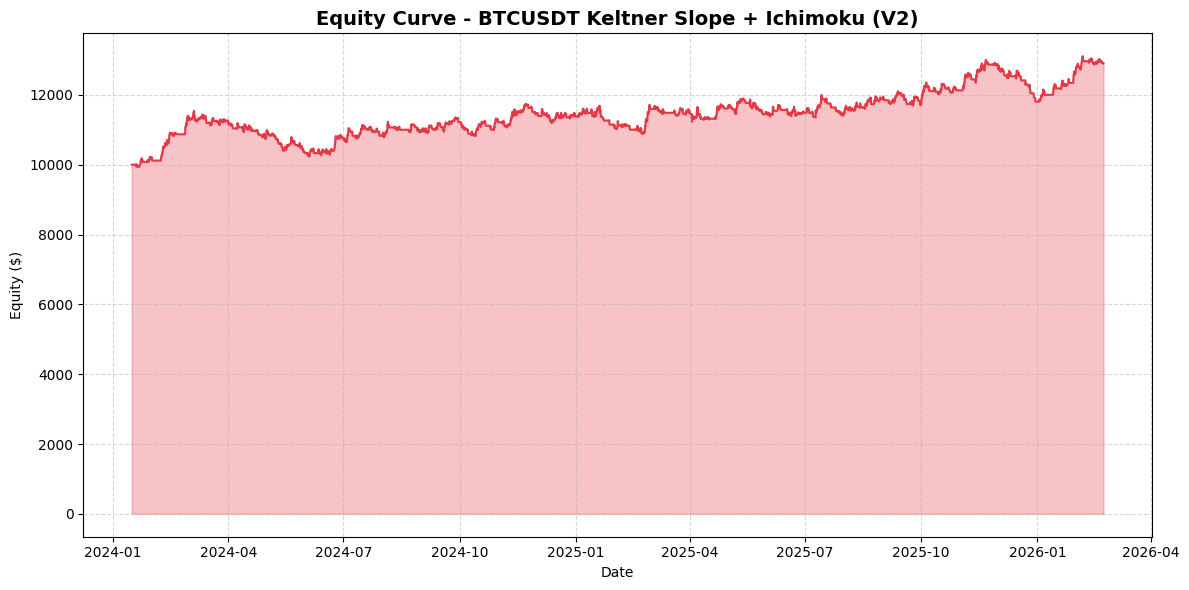


📊 Sample Trades (first 10):
            Exit Time   Type     Entry          Exit         PnL         Reason       Balance
0 2024-01-23 08:00:00  SHORT  41022.33  38774.456497  180.000000    Take Profit  10180.000000
1 2024-01-24 08:00:00  SHORT  39204.00  40432.478669 -101.800000      Stop Loss  10078.200000
2 2024-01-31 20:00:00   LONG  41823.51  42296.614092   38.688372  Trailing Stop  10116.888372
3 2024-02-08 12:00:00   LONG  43615.47  45183.977676  182.103991    Take Profit  10298.992362
4 2024-02-09 08:00:00   LONG  45284.13  46970.052617  185.381863    Take Profit  10484.374225
5 2024-02-12 12:00:00   LONG  47159.99  49094.155785  188.718736    Take Profit  10673.092961
6 2024-02-14 12:00:00   LONG  49532.02  51877.548309  192.115673    Take Profit  10865.208634
7 2024-02-19 20:00:00   LONG  51677.99  51774.730000    6.924140      Time Exit  10872.132774
8 2024-02-27 00:00:00   LONG  54487.10  56500.529015  195.698390    Take Profit  11067.831164
9 2024-02-28 08:00:00   LONG  5

In [16]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================================================
# 1) BINANCE DATA
# =========================================================
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data:
                break
            all_klines.extend(data)
            start_time = data[-1][0] + 1
            time.sleep(0.05)
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# =========================================================
# 2) INDICATORS (ATR + Keltner + Ichimoku standard 9/26/52)
# =========================================================
def calculate_indicators_v2(df):
    data = df.copy()

    # True Range
    data["prev_close"] = data["Close"].shift(1)
    h_l = data["High"] - data["Low"]
    h_pc = (data["High"] - data["prev_close"]).abs()
    l_pc = (data["Low"] - data["prev_close"]).abs()
    data["TR"] = pd.concat([h_l, h_pc, l_pc], axis=1).max(axis=1)

    def calc_atr(tr, period):
        return tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    data["ATR_20"] = calc_atr(data["TR"], 20)
    data["ATR_40"] = calc_atr(data["TR"], 40)
    data["ATR_90"] = calc_atr(data["TR"], 90)

    # Keltner (20, mult 2.3)
    data["EMA_20"] = data["Close"].ewm(span=20, adjust=False).mean()
    data["KC_Upper"] = data["EMA_20"] + (2.3 * data["ATR_20"])
    data["KC_Lower"] = data["EMA_20"] - (2.3 * data["ATR_20"])

    # Ichimoku standard 9/26/52
    tenkan_p = 9
    kijun_p = 26
    senkou_b_p = 52
    disp = 26

    tenkan_high = data["High"].rolling(tenkan_p).max()
    tenkan_low  = data["Low"].rolling(tenkan_p).min()
    data["Tenkan_Sen"] = (tenkan_high + tenkan_low) / 2

    kijun_high = data["High"].rolling(kijun_p).max()
    kijun_low  = data["Low"].rolling(kijun_p).min()
    data["Kijun_Sen"] = (kijun_high + kijun_low) / 2

    data["Senkou_A"] = ((data["Tenkan_Sen"] + data["Kijun_Sen"]) / 2).shift(disp)

    senkou_high = data["High"].rolling(senkou_b_p).max()
    senkou_low  = data["Low"].rolling(senkou_b_p).min()
    data["Senkou_B"] = ((senkou_high + senkou_low) / 2).shift(disp)

    data["Chikou"] = data["Close"].shift(-disp)

    # Helpers for Kumo filter
    data["Kumo_Top"] = data[["Senkou_A", "Senkou_B"]].max(axis=1)
    data["Kumo_Bot"] = data[["Senkou_A", "Senkou_B"]].min(axis=1)

    # ATR percent helper
    data["ATR20_PCT"] = data["ATR_20"] / data["Close"]

    data.dropna(inplace=True)
    return data

# =========================================================
# 3) BACKTESTER IMPROVED
# Improvements:
# - Fix Keltner slope direction (i-1 vs i-2)
# - Kumo regime filter: only long above cloud, only short below cloud
# - Stronger entry buffer (price_entry_mult default 1.2)
# - Trailing activates only after reaching +1R (profit >= SL_distance)
# - Optional vol filter: ATR20_PCT >= threshold
# =========================================================
class KeltnerIchimokuBacktesterV2:
    def __init__(self, df, initial_balance=10000):
        self.df = df
        self.initial_balance = float(initial_balance)
        self.balance = float(initial_balance)

        self.equity_curve = []
        self.trades = []

        # State
        self.position = None  # 'LONG'/'SHORT'/None
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.entry_bar_idx = 0
        self.qty = 0.0

        self.pending_order = None
        self.trailing_sl = None

        # ---- Strategy Parameters ----
        self.risk_pct = 0.01           # 1% per trade (not fee-adjusted)
        self.sl_coef = 2.0             # SL distance = 2 * ATR20
        self.tp_coef = 3.6             # TP distance = 3.6 * ATR20
        self.price_entry_mult = 1.2    # buffer vs ATR40 (was 0.8)
        self.trailing_coef = 2.0       # trailing distance = 2.0 * ATR90 (looser than 1.5)
        self.exit_after_bars = 30      # shorter time exit (was 40)
        self.pending_expiration = 6

        # ---- New Filters/Rules ----
        self.use_kumo_filter = True
        self.use_vol_filter = False
        self.min_atr20_pct = 0.004     # used if use_vol_filter=True

        # trailing activation
        self.trailing_after_R = 1.0    # start trailing after +1R
        self._initial_sl_dist = 0.0    # store SL distance (1R) at entry

    def run(self):
        indices = self.df.index

        for i in range(len(self.df)):
            bar = self.df.iloc[i]
            idx = indices[i]

            # A) Manage open position
            if self.position is not None:
                bars_held = i - self.entry_bar_idx

                # Time exit
                if bars_held >= self.exit_after_bars:
                    self.close_position(float(bar["Close"]), idx, "Time Exit")
                    self.append_equity(idx)
                    continue

                # Check exits (trailing -> SL -> TP)
                if self.position == "LONG":
                    # trailing hit
                    if self.trailing_sl is not None and float(bar["Low"]) <= self.trailing_sl:
                        self.close_position(self.trailing_sl, idx, "Trailing Stop")
                        self.append_equity(idx)
                        continue

                    # regular SL
                    if float(bar["Low"]) <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue

                    # TP
                    if float(bar["High"]) >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue

                    # Update trailing only after reaching +R
                    # profit_best = High - entry
                    profit_best = float(bar["High"]) - self.entry_price
                    if self._initial_sl_dist > 0 and (profit_best >= self.trailing_after_R * self._initial_sl_dist):
                        trailing_distance = self.trailing_coef * float(bar["ATR_90"])
                        new_trailing_sl = float(bar["Close"]) - trailing_distance
                        if self.trailing_sl is None or new_trailing_sl > self.trailing_sl:
                            self.trailing_sl = new_trailing_sl
                            self.sl = max(self.sl, self.trailing_sl)

                else:  # SHORT
                    if self.trailing_sl is not None and float(bar["High"]) >= self.trailing_sl:
                        self.close_position(self.trailing_sl, idx, "Trailing Stop")
                        self.append_equity(idx)
                        continue

                    if float(bar["High"]) >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue

                    if float(bar["Low"]) <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue

                    profit_best = self.entry_price - float(bar["Low"])
                    if self._initial_sl_dist > 0 and (profit_best >= self.trailing_after_R * self._initial_sl_dist):
                        trailing_distance = self.trailing_coef * float(bar["ATR_90"])
                        new_trailing_sl = float(bar["Close"]) + trailing_distance
                        if self.trailing_sl is None or new_trailing_sl < self.trailing_sl:
                            self.trailing_sl = new_trailing_sl
                            self.sl = min(self.sl, self.trailing_sl)

            # B) Manage pending order if flat
            if self.position is None and self.pending_order is not None:
                if i >= self.pending_order["expire_idx"]:
                    self.pending_order = None
                else:
                    p_price = float(self.pending_order["price"])
                    if self.pending_order["type"] == "BUY_STOP" and float(bar["High"]) >= p_price:
                        fill = max(p_price, float(bar["Open"]))  # gap-aware
                        self.open_position("LONG", fill, i, self.pending_order["sl_dist"], self.pending_order["tp_dist"])
                        self.pending_order = None

                    elif self.pending_order["type"] == "SELL_STOP" and float(bar["Low"]) <= p_price:
                        fill = min(p_price, float(bar["Open"]))
                        self.open_position("SHORT", fill, i, self.pending_order["sl_dist"], self.pending_order["tp_dist"])
                        self.pending_order = None

            # C) Create new pending if flat & no pending
            if self.position is None and self.pending_order is None:
                if i < 3:
                    self.append_equity(idx)
                    continue

                # Optional vol filter
                if self.use_vol_filter:
                    if float(self.df.iloc[i-1]["ATR20_PCT"]) < self.min_atr20_pct:
                        self.append_equity(idx)
                        continue

                # Keltner slope (FIXED direction)
                kc_upper_prev = float(self.df.iloc[i-2]["KC_Upper"])
                kc_upper_now  = float(self.df.iloc[i-1]["KC_Upper"])
                long_signal = (kc_upper_now > kc_upper_prev)

                kc_lower_prev = float(self.df.iloc[i-2]["KC_Lower"])
                kc_lower_now  = float(self.df.iloc[i-1]["KC_Lower"])
                short_signal = (kc_lower_now < kc_lower_prev)

                # Kumo regime filter
                if self.use_kumo_filter:
                    close_prev = float(self.df.iloc[i-1]["Close"])
                    kumo_top = float(self.df.iloc[i-1]["Kumo_Top"])
                    kumo_bot = float(self.df.iloc[i-1]["Kumo_Bot"])
                    above_cloud = close_prev > kumo_top
                    below_cloud = close_prev < kumo_bot

                    # enforce regime
                    long_signal = long_signal and above_cloud
                    short_signal = short_signal and below_cloud

                # Entry anchor: Tenkan (shift=3) +/- ATR40 buffer (shift=3)
                tenkan_shift3 = float(self.df.iloc[i-3]["Tenkan_Sen"])
                atr40_shift3 = float(self.df.iloc[i-3]["ATR_40"])

                # SL/TP distances based on ATR20 (shift=1)
                atr20_shift1 = float(self.df.iloc[i-1]["ATR_20"])
                sl_distance = self.sl_coef * atr20_shift1
                tp_distance = self.tp_coef * atr20_shift1

                if long_signal:
                    entry_price = tenkan_shift3 + (self.price_entry_mult * atr40_shift3)
                    self.pending_order = {
                        "type": "BUY_STOP",
                        "price": entry_price,
                        "sl_dist": sl_distance,
                        "tp_dist": tp_distance,
                        "expire_idx": i + self.pending_expiration
                    }

                elif short_signal and not long_signal:
                    entry_price = tenkan_shift3 - (self.price_entry_mult * atr40_shift3)
                    self.pending_order = {
                        "type": "SELL_STOP",
                        "price": entry_price,
                        "sl_dist": sl_distance,
                        "tp_dist": tp_distance,
                        "expire_idx": i + self.pending_expiration
                    }

            # D) Append equity
            self.append_equity(idx)

    def append_equity(self, idx):
        mtm = self.balance
        current_price = float(self.df.loc[idx, "Close"])

        if self.position == "LONG":
            mtm += (current_price - self.entry_price) * self.qty
        elif self.position == "SHORT":
            mtm += (self.entry_price - current_price) * self.qty

        self.equity_curve.append({"time": idx, "equity": mtm})

    def open_position(self, pos_type, price, bar_idx, sl_dist, tp_dist):
        self.position = pos_type
        self.entry_price = float(price)
        self.entry_bar_idx = int(bar_idx)

        # SL/TP
        if pos_type == "LONG":
            self.sl = self.entry_price - float(sl_dist)
            self.tp = self.entry_price + float(tp_dist)
        else:
            self.sl = self.entry_price + float(sl_dist)
            self.tp = self.entry_price - float(tp_dist)

        # store 1R
        self._initial_sl_dist = abs(self.entry_price - self.sl)

        # trailing reset
        self.trailing_sl = None

        # qty by fixed risk %
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(self.entry_price - self.sl)
        self.qty = (risk_amount / sl_distance) if sl_distance > 0 else 0.0

    def close_position(self, price, time_idx, reason):
        price = float(price)
        if self.position == "LONG":
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty

        self.balance += pnl

        self.trades.append({
            "Exit Time": time_idx,
            "Type": self.position,
            "Entry": self.entry_price,
            "Exit": price,
            "PnL": pnl,
            "Reason": reason,
            "Balance": self.balance
        })

        # reset
        self.position = None
        self.qty = 0.0
        self.trailing_sl = None
        self._initial_sl_dist = 0.0

# =========================================================
# 4) METRICS
# =========================================================
def calculate_advanced_metrics(trades_df, equity_data, initial_balance):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index("time", inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = float(eq_df["equity"].iloc[-1])
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0.0
    cagr = ((final_equity / initial_balance) ** (1/years) - 1) if years > 0 else 0.0

    running_max = eq_df["equity"].cummax()
    dd = (eq_df["equity"] - running_max) / running_max
    max_dd = float(dd.min())

    eq_df["returns"] = eq_df["equity"].pct_change()
    mean_ret = eq_df["returns"].mean()
    std_ret = eq_df["returns"].std()
    bars_per_year = (len(eq_df) / years) if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret and std_ret != 0 else 0.0

    total_trades = len(trades_df)
    win_trades = int((trades_df["PnL"] > 0).sum()) if total_trades > 0 else 0
    win_rate = win_trades / total_trades if total_trades > 0 else 0.0
    avg_pnl = trades_df["PnL"].mean() if total_trades > 0 else 0.0

    gross_profit = trades_df.loc[trades_df["PnL"] > 0, "PnL"].sum() if total_trades > 0 else 0.0
    gross_loss = abs(trades_df.loc[trades_df["PnL"] < 0, "PnL"].sum()) if total_trades > 0 else 0.0
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0.0

    return {
        "Final Equity": final_equity,
        "Total Return": total_return,
        "CAGR (approx)": cagr,
        "Max Drawdown": max_dd,
        "Sharpe": sharpe,
        "Trades": total_trades,
        "Winrate": win_rate,
        "Avg PnL/Trade": avg_pnl,
        "Profit Factor": profit_factor,
        "equity_df": eq_df
    }

def print_report_and_plot(metrics, symbol):
    print("\n" + "=" * 60)
    print("METRICS (Keltner Slope + Ichimoku Strategy) - IMPROVED V2")
    print("=" * 60)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print("=" * 60)

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5, color="#E63946")
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.3, color="#E63946")
    plt.title(f"Equity Curve - {symbol} Keltner Slope + Ichimoku (V2)", fontsize=14, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

# =========================================================
# 5) MAIN
# =========================================================
if __name__ == "__main__":
    symbol = "BTCUSDT"
    interval = "4h"
    start_date = "01/01/2024"
    end_date = "26/02/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) <= 300:
        print("❌ Không đủ dữ liệu.")
        raise SystemExit

    print("✅ Dữ liệu sẵn sàng. Tính toán Indicators...")
    df_calc = calculate_indicators_v2(df_raw)

    print("🚀 Đang chạy Backtest Keltner + Ichimoku Strategy (IMPROVED V2)...")
    bt = KeltnerIchimokuBacktesterV2(df_calc, initial_balance=10000)

    # ===== Toggle filters here =====
    bt.use_kumo_filter = True
    bt.use_vol_filter = False
    bt.min_atr20_pct = 0.004

    # ===== Tune here =====
    bt.price_entry_mult = 1.2
    bt.trailing_coef = 2.0
    bt.trailing_after_R = 1.0
    bt.exit_after_bars = 30

    bt.run()

    trades_df = pd.DataFrame(bt.trades)
    if trades_df.empty:
        print("⚠️ Không có lệnh nào được thực hiện.")
        raise SystemExit

    metrics = calculate_advanced_metrics(trades_df, bt.equity_curve, bt.initial_balance)
    print_report_and_plot(metrics, symbol)

    print("\n📊 Sample Trades (first 10):")
    print(trades_df.head(10).to_string())

    print("\n📊 Exit Reasons Distribution:")
    print(trades_df["Reason"].value_counts())

⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Dữ liệu sẵn sàng. Tính toán Indicators...
🚀 Đang chạy Backtest Keltner + Ichimoku Strategy (V3)...

METRICS (Keltner + Ichimoku) - V3 (Less Trades Filters)
     Final Equity: 11145.0070
     Total Return: 0.1145
    CAGR (approx): 0.0559
     Max Drawdown: -0.1474
           Sharpe: 0.3955
           Trades: 463
          Winrate: 0.4233
    Avg PnL/Trade: 2.4730
    Profit Factor: 1.0445


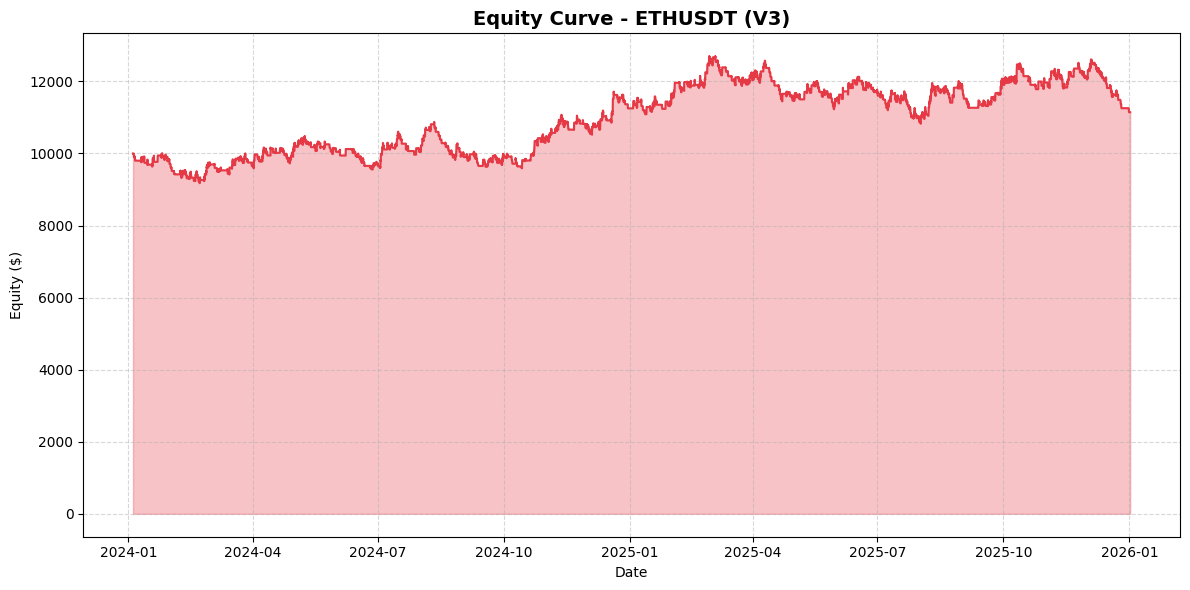


📊 Sample Trades (first 10):
            Exit Time   Type        Entry         Exit         PnL         Reason      Balance
0 2024-01-05 01:00:00   LONG  2278.597067  2233.089553 -100.000000      Stop Loss  9900.000000
1 2024-01-05 23:00:00  SHORT  2221.800624  2262.777618  -99.000000      Stop Loss  9801.000000
2 2024-01-10 17:00:00   LONG  2386.800000  2402.095869   24.614544  Trailing Stop  9825.614544
3 2024-01-12 10:00:00   LONG  2613.000000  2620.930000    9.363734      Time Exit  9834.978279
4 2024-01-12 17:00:00   LONG  2650.520000  2588.054412  -95.435436  Trailing Stop  9739.542843
5 2024-01-15 09:00:00  SHORT  2506.873142  2524.758260  -48.272948  Trailing Stop  9691.269895
6 2024-01-18 18:00:00  SHORT  2520.122402  2456.030287  174.442858    Take Profit  9865.712753
7 2024-01-19 18:00:00  SHORT  2452.896167  2485.641245  -98.657128      Stop Loss  9767.055626
8 2024-01-22 09:00:00  SHORT  2430.170000  2385.396406  175.807001    Take Profit  9942.862627
9 2024-01-26 02:00:00

In [19]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================================================
# 1) BINANCE DATA
# =========================================================
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            r = requests.get(general_url, params=params, timeout=10)
            if r.status_code != 200:
                print("Error:", r.status_code, r.text)
                break
            data = r.json()
            if not data:
                break
            all_klines.extend(data)
            start_time = data[-1][0] + 1
            time.sleep(0.05)
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# =========================================================
# 2) INDICATORS (ATR + Keltner + Ichimoku standard 9/26/52)
# =========================================================
def calculate_indicators_v3(df):
    data = df.copy()

    # True Range
    data["prev_close"] = data["Close"].shift(1)
    h_l = data["High"] - data["Low"]
    h_pc = (data["High"] - data["prev_close"]).abs()
    l_pc = (data["Low"] - data["prev_close"]).abs()
    data["TR"] = pd.concat([h_l, h_pc, l_pc], axis=1).max(axis=1)

    def calc_atr(tr, period):
        return tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    data["ATR_20"] = calc_atr(data["TR"], 20)
    data["ATR_40"] = calc_atr(data["TR"], 40)
    data["ATR_90"] = calc_atr(data["TR"], 90)

    # Keltner (20, mult 2.3)
    data["EMA_20"] = data["Close"].ewm(span=20, adjust=False).mean()
    data["KC_Upper"] = data["EMA_20"] + (2.3 * data["ATR_20"])
    data["KC_Lower"] = data["EMA_20"] - (2.3 * data["ATR_20"])

    # Ichimoku standard 9/26/52
    tenkan_p = 9
    kijun_p = 26
    senkou_b_p = 52
    disp = 26

    tenkan_high = data["High"].rolling(tenkan_p).max()
    tenkan_low  = data["Low"].rolling(tenkan_p).min()
    data["Tenkan_Sen"] = (tenkan_high + tenkan_low) / 2

    kijun_high = data["High"].rolling(kijun_p).max()
    kijun_low  = data["Low"].rolling(kijun_p).min()
    data["Kijun_Sen"] = (kijun_high + kijun_low) / 2

    data["Senkou_A"] = ((data["Tenkan_Sen"] + data["Kijun_Sen"]) / 2).shift(disp)

    senkou_high = data["High"].rolling(senkou_b_p).max()
    senkou_low  = data["Low"].rolling(senkou_b_p).min()
    data["Senkou_B"] = ((senkou_high + senkou_low) / 2).shift(disp)

    data["Chikou"] = data["Close"].shift(-disp)

    # Kumo helpers
    data["Kumo_Top"] = data[["Senkou_A", "Senkou_B"]].max(axis=1)
    data["Kumo_Bot"] = data[["Senkou_A", "Senkou_B"]].min(axis=1)

    # Vol helper
    data["ATR20_PCT"] = data["ATR_20"] / data["Close"]

    data.dropna(inplace=True)
    return data

# =========================================================
# 3) BACKTESTER V3
# Adds:
# - Vol filter (ATR20_PCT)
# - KC slope strength threshold
# - Cooldown after close
# - Kumo thickness filter
# Keeps:
# - pending stop entries anchored on Tenkan +/- ATR40 buffer
# - SL/TP ATR20
# - trailing ATR90 (activates after +R)
# - time exit
# =========================================================
class KeltnerIchimokuBacktesterV3:
    def __init__(self, df, initial_balance=10000.0):
        self.df = df
        self.initial_balance = float(initial_balance)
        self.balance = float(initial_balance)

        self.equity_curve = []
        self.trades = []

        # State
        self.position = None  # 'LONG'/'SHORT'/None
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.entry_bar_idx = 0
        self.qty = 0.0
        self.trailing_sl = None

        self.pending_order = None

        # ---- Base Parameters ----
        self.risk_pct = 0.01
        self.sl_coef = 2.0
        self.tp_coef = 3.6
        self.price_entry_mult = 1.4      # higher to reduce fills
        self.trailing_coef = 2.0
        self.trailing_after_R = 1.0
        self.exit_after_bars = 30
        self.pending_expiration = 6

        # ---- Filters ----
        self.use_kumo_filter = True

        self.use_vol_filter = True
        self.min_atr20_pct = 0.005       # raise to reduce trades (0.004~0.006)

        self.use_kc_slope_strength = True
        self.kc_slope_thr_pct = 0.0008   # 0.08% slope threshold (tune 0.0003~0.0015)

        self.use_kumo_thickness = True
        self.kumo_thickness_atr_mult = 0.8  # thickness >= 0.8*ATR20

        # ---- Cooldown ----
        self.cooldown_bars = 12
        self.next_entry_idx = 0

        # internal
        self._initial_sl_dist = 0.0

    def run(self):
        idxs = self.df.index

        for i in range(len(self.df)):
            bar = self.df.iloc[i]
            idx = idxs[i]

            # A) Manage open position
            if self.position is not None:
                bars_held = i - self.entry_bar_idx

                # time exit
                if bars_held >= self.exit_after_bars:
                    self.close_position(float(bar["Close"]), idx, "Time Exit")
                    self.append_equity(idx)
                    continue

                # exits + trailing update
                if self.position == "LONG":
                    if self.trailing_sl is not None and float(bar["Low"]) <= self.trailing_sl:
                        self.close_position(self.trailing_sl, idx, "Trailing Stop")
                        self.append_equity(idx)
                        continue
                    if float(bar["Low"]) <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    if float(bar["High"]) >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue

                    profit_best = float(bar["High"]) - self.entry_price
                    if self._initial_sl_dist > 0 and profit_best >= self.trailing_after_R * self._initial_sl_dist:
                        new_trailing_sl = float(bar["Close"]) - self.trailing_coef * float(bar["ATR_90"])
                        if self.trailing_sl is None or new_trailing_sl > self.trailing_sl:
                            self.trailing_sl = new_trailing_sl
                            self.sl = max(self.sl, self.trailing_sl)

                else:  # SHORT
                    if self.trailing_sl is not None and float(bar["High"]) >= self.trailing_sl:
                        self.close_position(self.trailing_sl, idx, "Trailing Stop")
                        self.append_equity(idx)
                        continue
                    if float(bar["High"]) >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    if float(bar["Low"]) <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue

                    profit_best = self.entry_price - float(bar["Low"])
                    if self._initial_sl_dist > 0 and profit_best >= self.trailing_after_R * self._initial_sl_dist:
                        new_trailing_sl = float(bar["Close"]) + self.trailing_coef * float(bar["ATR_90"])
                        if self.trailing_sl is None or new_trailing_sl < self.trailing_sl:
                            self.trailing_sl = new_trailing_sl
                            self.sl = min(self.sl, self.trailing_sl)

            # B) Manage pending if flat
            if self.position is None and self.pending_order is not None:
                if i >= self.pending_order["expire_idx"]:
                    self.pending_order = None
                else:
                    p_price = float(self.pending_order["price"])
                    if self.pending_order["type"] == "BUY_STOP" and float(bar["High"]) >= p_price:
                        fill = max(p_price, float(bar["Open"]))
                        self.open_position("LONG", fill, i, self.pending_order["sl_dist"], self.pending_order["tp_dist"])
                        self.pending_order = None
                    elif self.pending_order["type"] == "SELL_STOP" and float(bar["Low"]) <= p_price:
                        fill = min(p_price, float(bar["Open"]))
                        self.open_position("SHORT", fill, i, self.pending_order["sl_dist"], self.pending_order["tp_dist"])
                        self.pending_order = None

            # C) Create new pending if flat & no pending
            if self.position is None and self.pending_order is None:
                # cooldown gate
                if i < self.next_entry_idx:
                    self.append_equity(idx)
                    continue

                if i < 3:
                    self.append_equity(idx)
                    continue

                # vol filter (ATR20_PCT)
                if self.use_vol_filter:
                    if float(self.df.iloc[i-1]["ATR20_PCT"]) < self.min_atr20_pct:
                        self.append_equity(idx)
                        continue

                # KC slope (direction fixed)
                kc_upper_prev = float(self.df.iloc[i-2]["KC_Upper"])
                kc_upper_now  = float(self.df.iloc[i-1]["KC_Upper"])
                kc_lower_prev = float(self.df.iloc[i-2]["KC_Lower"])
                kc_lower_now  = float(self.df.iloc[i-1]["KC_Lower"])

                upper_slope = (kc_upper_now - kc_upper_prev) / max(abs(kc_upper_prev), 1e-9)
                lower_slope = (kc_lower_now - kc_lower_prev) / max(abs(kc_lower_prev), 1e-9)

                long_signal = upper_slope > 0
                short_signal = lower_slope < 0

                # slope strength
                if self.use_kc_slope_strength:
                    long_signal = long_signal and (upper_slope >= self.kc_slope_thr_pct)
                    short_signal = short_signal and (abs(lower_slope) >= self.kc_slope_thr_pct)

                # Kumo regime + thickness
                if self.use_kumo_filter:
                    close_prev = float(self.df.iloc[i-1]["Close"])
                    kumo_top = float(self.df.iloc[i-1]["Kumo_Top"])
                    kumo_bot = float(self.df.iloc[i-1]["Kumo_Bot"])
                    above_cloud = close_prev > kumo_top
                    below_cloud = close_prev < kumo_bot

                    long_signal = long_signal and above_cloud
                    short_signal = short_signal and below_cloud

                    if self.use_kumo_thickness:
                        thickness = kumo_top - kumo_bot
                        atr20 = float(self.df.iloc[i-1]["ATR_20"])
                        if thickness < self.kumo_thickness_atr_mult * atr20:
                            long_signal = False
                            short_signal = False

                # Entry anchor (Tenkan shift=3) +/- ATR40 buffer (shift=3)
                tenkan_shift3 = float(self.df.iloc[i-3]["Tenkan_Sen"])
                atr40_shift3 = float(self.df.iloc[i-3]["ATR_40"])

                # SL/TP distances from ATR20 shift=1
                atr20_shift1 = float(self.df.iloc[i-1]["ATR_20"])
                sl_dist = self.sl_coef * atr20_shift1
                tp_dist = self.tp_coef * atr20_shift1

                if long_signal:
                    entry_price = tenkan_shift3 + (self.price_entry_mult * atr40_shift3)
                    self.pending_order = {
                        "type": "BUY_STOP",
                        "price": entry_price,
                        "sl_dist": sl_dist,
                        "tp_dist": tp_dist,
                        "expire_idx": i + self.pending_expiration
                    }
                elif short_signal and not long_signal:
                    entry_price = tenkan_shift3 - (self.price_entry_mult * atr40_shift3)
                    self.pending_order = {
                        "type": "SELL_STOP",
                        "price": entry_price,
                        "sl_dist": sl_dist,
                        "tp_dist": tp_dist,
                        "expire_idx": i + self.pending_expiration
                    }

            # D) Equity
            self.append_equity(idx)

    def append_equity(self, idx):
        mtm = self.balance
        px = float(self.df.loc[idx, "Close"])
        if self.position == "LONG":
            mtm += (px - self.entry_price) * self.qty
        elif self.position == "SHORT":
            mtm += (self.entry_price - px) * self.qty
        self.equity_curve.append({"time": idx, "equity": mtm})

    def open_position(self, pos_type, price, bar_idx, sl_dist, tp_dist):
        self.position = pos_type
        self.entry_price = float(price)
        self.entry_bar_idx = int(bar_idx)

        if pos_type == "LONG":
            self.sl = self.entry_price - float(sl_dist)
            self.tp = self.entry_price + float(tp_dist)
        else:
            self.sl = self.entry_price + float(sl_dist)
            self.tp = self.entry_price - float(tp_dist)

        self._initial_sl_dist = abs(self.entry_price - self.sl)
        self.trailing_sl = None

        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(self.entry_price - self.sl)
        self.qty = (risk_amount / sl_distance) if sl_distance > 0 else 0.0

    def close_position(self, price, time_idx, reason):
        price = float(price)
        if self.position == "LONG":
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty

        self.balance += pnl
        self.trades.append({
            "Exit Time": time_idx,
            "Type": self.position,
            "Entry": self.entry_price,
            "Exit": price,
            "PnL": pnl,
            "Reason": reason,
            "Balance": self.balance
        })

        # set cooldown from current bar
        self.next_entry_idx = int(self.entry_bar_idx) + int(self.cooldown_bars)

        # reset
        self.position = None
        self.qty = 0.0
        self.trailing_sl = None
        self._initial_sl_dist = 0.0

# =========================================================
# 4) METRICS
# =========================================================
def calculate_advanced_metrics(trades_df, equity_data, initial_balance):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index("time", inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = float(eq_df["equity"].iloc[-1])
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0.0
    cagr = ((final_equity / initial_balance) ** (1/years) - 1) if years > 0 else 0.0

    running_max = eq_df["equity"].cummax()
    dd = (eq_df["equity"] - running_max) / running_max
    max_dd = float(dd.min())

    eq_df["returns"] = eq_df["equity"].pct_change()
    mean_ret = eq_df["returns"].mean()
    std_ret = eq_df["returns"].std()
    bars_per_year = (len(eq_df) / years) if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret and std_ret != 0 else 0.0

    total_trades = len(trades_df)
    win_trades = int((trades_df["PnL"] > 0).sum()) if total_trades > 0 else 0
    win_rate = win_trades / total_trades if total_trades > 0 else 0.0
    avg_pnl = trades_df["PnL"].mean() if total_trades > 0 else 0.0

    gross_profit = trades_df.loc[trades_df["PnL"] > 0, "PnL"].sum() if total_trades > 0 else 0.0
    gross_loss = abs(trades_df.loc[trades_df["PnL"] < 0, "PnL"].sum()) if total_trades > 0 else 0.0
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0.0

    return {
        "Final Equity": final_equity,
        "Total Return": total_return,
        "CAGR (approx)": cagr,
        "Max Drawdown": max_dd,
        "Sharpe": sharpe,
        "Trades": total_trades,
        "Winrate": win_rate,
        "Avg PnL/Trade": avg_pnl,
        "Profit Factor": profit_factor,
        "equity_df": eq_df
    }

def print_report_and_plot(metrics, symbol):
    print("\n" + "=" * 70)
    print("METRICS (Keltner + Ichimoku) - V3 (Less Trades Filters)")
    print("=" * 70)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print("=" * 70)

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5, color="#E63946")
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.3, color="#E63946")
    plt.title(f"Equity Curve - {symbol} (V3)", fontsize=14, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

# =========================================================
# 5) MAIN
# =========================================================
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2024"
    end_date = "02/01/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)
    if len(df_raw) <= 300:
        print("❌ Không đủ dữ liệu.")
        raise SystemExit

    print("✅ Dữ liệu sẵn sàng. Tính toán Indicators...")
    df_calc = calculate_indicators_v3(df_raw)

    print("🚀 Đang chạy Backtest Keltner + Ichimoku Strategy (V3)...")
    bt = KeltnerIchimokuBacktesterV3(df_calc, initial_balance=10000)

    # ===== Quick tune knobs (reduce trades) =====
    bt.min_atr20_pct = 0.005
    bt.kc_slope_thr_pct = 0.0008
    bt.kumo_thickness_atr_mult = 0.8
    bt.cooldown_bars = 12
    bt.price_entry_mult = 1.4
    # ===========================================

    bt.run()

    trades_df = pd.DataFrame(bt.trades)
    if trades_df.empty:
        print("⚠️ Không có lệnh nào được thực hiện.")
        raise SystemExit

    metrics = calculate_advanced_metrics(trades_df, bt.equity_curve, bt.initial_balance)
    print_report_and_plot(metrics, symbol)

    print("\n📊 Sample Trades (first 10):")
    print(trades_df.head(10).to_string())

    print("\n📊 Exit Reasons Distribution:")
    print(trades_df["Reason"].value_counts())